# Part 1 
## Electronic Arts (EA) — From NA Publisher to Global Powerhouse  
**A data-driven history from the `vgsales.csv` dataset**  

This notebook processes your uploaded dataset at **`vgsales.csv`** and produces a full analytical report on EA’s evolution into a global company.

**Sections**
1. Setup & Load  
3. Global Timeline (Annual Sales)  
6. Genre Heatmap (Year × Genre)  
7. Top Titles (Table + Chart)   
9. Hit Rate & Title Volume  

## Setup & Data Loading
Import libraries, load the CSV, standardize columns, coerce `Year`, and focus on **Electronic Arts**.  
We also save a cleaned EA subset for reuse.

In [1]:
# --- Setup & Data Loading ------------------------------------------------------------
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
import seaborn as sns

# Path to uploaded dataset (place the file here or update the path)
DATA_PATH = Path("vgsales.csv")

# Load
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip() for c in df.columns]

# Expect Kaggle-like columns
expected = {"Name","Platform","Year","Genre","Publisher",
            "NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"}
missing = expected - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Year -> numeric
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# EA subset
ea = df[df["Publisher"].str.lower() == "electronic arts"].dropna(subset=["Year"]).copy()
ea["Year"] = ea["Year"].astype(int)
ea = ea[(ea["Year"] >= 1985) & (ea["Year"] <= 2020)].copy()

print(f"EA rows: {ea.shape[0]} | years: {ea['Year'].min()}–{ea['Year'].max()} | titles: {ea['Name'].nunique()}")


EA rows: 1339 | years: 1992–2016 | titles: 605


## Task: Plot the Timeline of EA’s Global Sales

In this activity, you will analyze the **global sales performance** of Electronic Arts (EA) over time.  

**Your objectives are:**
1. Group the dataset by `Year` and calculate the **total Global_Sales** for each year.  
2. Sort the results chronologically to create a clean timeline.  
3. Use a **line plot** to visualize how EA’s global sales changed across years.  
4. Make sure to add:
   - A descriptive **title** for the chart.  
   - Axis labels (`Year`, `Global Sales (Millions)`).  
   - A **legend** to clarify what the line represents.  
5. Format the chart so it is **readable and clear** (adjust figure size, apply `tight_layout()`, etc.).  

**Question to reflect on:**  
- What patterns or trends can you observe in EA’s sales performance over the years? Are there peaks, declines, or steady periods?

#### Explanatory report for sales timeline

I grouped the EA rows by `Year` and summed `Global_Sales`. I sorted the totals by year and plotted them as a line chart with a marker for each year.

Year
1992     0.06
1994     0.65
1995     3.33
1996     7.90
1997    22.94
1998    29.95
1999    20.15
2000    25.13
2001    45.12
2002    73.01
2003    69.83
2004    67.33
2005    67.01
2006    58.41
2007    71.33
2008    84.12
2009    86.20
2010    81.38
2011    72.25
2012    49.90
2013    52.92
2014    46.80
2015    45.42
2016    12.25
Name: Global_Sales, dtype: float64

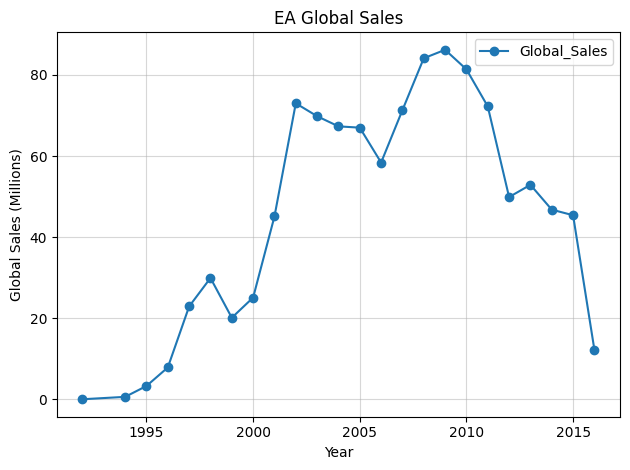

In [2]:
#TODO: Implement the tasks below

total_global_sales_by_year = ea.groupby("Year")["Global_Sales"].sum().sort_index() # group by year, sum global_sales col, and sort by year
display(total_global_sales_by_year)


total_global_sales_by_year.plot(kind="line", marker="o", title="EA Global Sales") # line plot with a marker on each year

# plot labels, legend, and layout
plt.xlabel("Year")
plt.ylabel("Global Sales (Millions)")
plt.legend()
plt.grid(alpha=0.5)

plt.tight_layout()
plt.show()


From the chart, I can tell that EA's recorded sales are near zero in 1992 and 1994, and from 1995, there was pretty much a constant increase from till 2009, with a tiny dip in 1999, and a minor multi-year decrease from 2002-2006, peaking at 86.20 million sales in 2009. Then from 2009 to 2015, sales started to drop largely, with the largest dip from 1 year to another happing at 2014 to 2015, dropping from 45.42 million sales to 12.25.

## Task: Visualize EA Genre Sales with a Heatmap  

In this activity, you will examine how **Electronic Arts (EA)** game sales varied across different **genres** and **years** using a heatmap.  

**Your objectives are:**  
1. Group the dataset by both `Year` and `Genre`, and calculate the **total Global_Sales** for each combination.  
2. Reshape the results into a **pivot-style table** where rows represent genres and columns represent years.  
3. Create a **heatmap** to visualize the distribution of sales values across genres and years.  
4. Enhance readability by:  
   - Using an appropriate **color palette** to represent sales volume.  
   - Adding a **colorbar** with a clear label (e.g., “Global Sales (Millions)”).  
   - Rotating x-axis labels so that years are easy to read.  
   - Making sure the plot has a descriptive **title** and properly labeled axes.  

**Question to reflect on:**  
- Which genres dominated EA’s sales in different periods? Do you notice any emerging or declining trends in certain genres over time?

#### Explanatory report for the genre heatmap

I grouped EA sales by `Year` and `Genre`, then pivoted the table so genres are rows and years are columns. I displayed that table and plotted it with `sns.heatmap`.

Year,1992,1994,1995,1996,1997,1998,1999,2000,2001,2002,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
Genre,,,,,,,,,,,,,,,,,,,,,
Action,NaN,NaN,NaN,0.82,1.02,0.08,0.27,2.47,7.21,14.73,...,11.26,4.25,10.77,5.62,12.68,22.17,1.99,NaN,0.87,NaN
Adventure,NaN,NaN,0.01,0.05,NaN,0.60,NaN,NaN,NaN,0.20,...,0.16,NaN,2.13,NaN,1.22,NaN,NaN,NaN,NaN,NaN
Fighting,NaN,NaN,NaN,NaN,1.52,1.50,3.12,0.41,2.07,NaN,...,NaN,0.58,2.94,0.74,1.95,NaN,NaN,NaN,NaN,NaN
Misc,NaN,NaN,0.32,NaN,NaN,0.09,NaN,2.99,NaN,0.05,...,2.42,6.21,3.13,3.15,0.82,NaN,NaN,NaN,NaN,NaN
Platform,NaN,NaN,NaN,NaN,NaN,0.61,NaN,NaN,NaN,1.88,...,NaN,2.31,0.06,NaN,NaN,NaN,NaN,NaN,NaN,0.52
Puzzle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.25,0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Racing,NaN,NaN,2.32,2.29,2.70,8.49,8.38,3.31,7.48,6.34,...,9.02,12.07,8.42,5.89,1.32,5.71,5.39,NaN,3.07,0.03
Role-Playing,NaN,NaN,NaN,NaN,0.58,NaN,NaN,NaN,0.66,NaN,...,0.08,0.68,4.77,4.30,4.57,7.85,NaN,4.81,NaN,NaN
Shooter,NaN,NaN,0.19,NaN,NaN,2.67,3.21,0.97,3.74,17.86,...,7.86,12.60,5.56,15.31,22.36,0.18,17.28,8.09,15.96,0.94


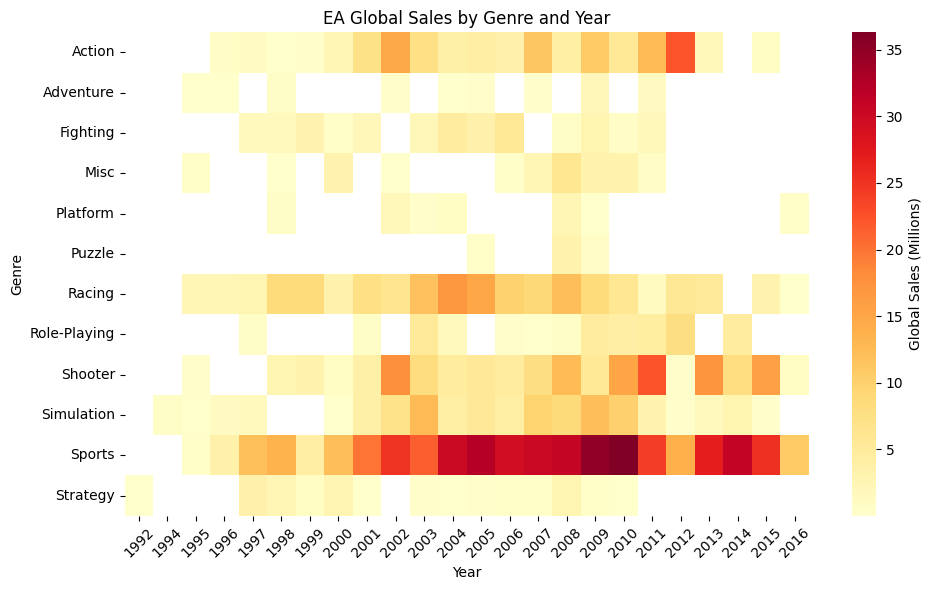

In [3]:
#TODO: Implement the tasks below

# group by year and genre, sum global sales col, reset index so we can convert it back to df to pivot
total_global_sales_by_year_and_genre = ea.groupby(["Year", "Genre"])["Global_Sales"].sum().reset_index()

# pivot so genre is the index, years represent the columns, and each cell is populated with global sales for that year
total_global_sales_by_year_and_genre = total_global_sales_by_year_and_genre.pivot(index="Genre", columns="Year", values="Global_Sales")

display(total_global_sales_by_year_and_genre)

# plot
plt.figure(figsize=(10, 6))
# heatmap
sns.heatmap(total_global_sales_by_year_and_genre, cmap="YlOrRd", cbar_kws={"label": "Global Sales (Millions)"})

plt.title("EA Global Sales by Genre and Year")
plt.xlabel("Year")
plt.ylabel("Genre")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

From the heatmap, the Sports genre pretty much dominates EA's sales. Racing leads a little at the start, with Shooting gaining some popularity in the 2000s, Action gaining popularity, then losing it twice from 1996 to 2012. Simulation also grows in popularity during the 2000s, and again fades out. Most other genres remain small or fade away completely throughout the years.


## Task: Identify EA’s Top-Selling Titles  

In this activity, you will analyze which **individual games** brought in the most global sales for Electronic Arts (EA).  

**Your objectives are:**  
1. Group the dataset by the `Name` of each game and calculate the **total Global_Sales** per title.  
2. Sort the results in descending order to find the **top 20 games**.  
3. Create a **horizontal bar chart** showing the sales of these top 20 titles.  
4. Make the visualization clearer by:  
   - Labeling each bar with the corresponding **game name**.  
   - Adding a descriptive **title** and labeling the x-axis as “Global Sales (Millions)”.  
   - Inverting the y-axis so that the **highest-selling game appears at the top**.  
   - Adjusting the figure size and layout for readability.  

**Question to reflect on:**  
- Which EA game titles stand out as global bestsellers? Do you notice any patterns about the types of games that dominate the top ranks?

#### Explanatory report for the top titles

I grouped EA games by `Name`, summed `Global_Sales`, and kept the 20 highest totals. I plotted those titles with a horizontal bar chart.

,Name,Global_Sales
0,FIFA 15,19.02
1,Battlefield 3,17.36
2,FIFA 14,17.14
3,FIFA 16,16.44
4,FIFA Soccer 13,16.16
5,The Sims 3,15.45
6,Need for Speed: Most Wanted,14.08
7,Battlefield 4,14.03
8,FIFA 12,13.15
9,FIFA Soccer 11,12.56


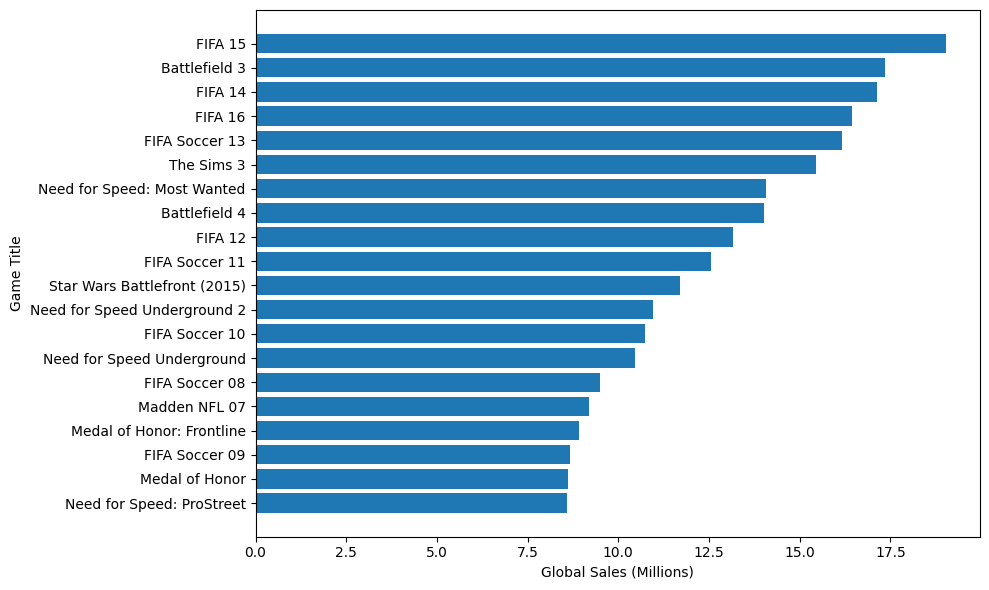

In [4]:
#TODO Implement your tasks here

# group by name, sum global sales col, sort global sales by descending, take first 20
total_global_sales_by_name = ea.groupby("Name")["Global_Sales"].sum().sort_values(ascending=False).head(20).reset_index()

display(total_global_sales_by_name)

plt.figure(figsize=(10, 6))

# horizontal plot, X = global sales, Y = game title
plt.barh(total_global_sales_by_name["Name"], total_global_sales_by_name["Global_Sales"])

# plot
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Game Title")
plt.gca().invert_yaxis() # invert bars so highest global sales is first
plt.tight_layout()
plt.show()




EA's global best sellers are dominated by yearly FIFA releases, of the 20 top games, 9 of them are FIFA games. Shooter games such as Battlefield 3 and 4, Star Wars Battlefront, and Medal of Honor are also all amongst the top 20, followed by racing games such as the 4 Need for Speed games, and lastly, The Sims 3 is the main title outside of those 3 groups, and it ranks 6th overall in Global Sales.


# Part 2: Schema Matching with Jaccard Similarity

**Objective:** In this exercise, you will implement a schema matching algorithm to identify corresponding columns between two different datasets. We will use a combination of column **name similarity** and column **value similarity** to find the best matches.

This notebook is divided into the following sections:

1.  **Understanding Jaccard Similarity:** A brief explanation of the core algorithm.
2.  **Loading and Inspection:** Load the CSVs into Pandas DataFrames and examine their structure.
3.  **The Programming Exercise:** The main task where you will complete the Python code.


## Understanding Jaccard Similarity
The Jaccard similarity coefficient measures the similarity between two sets. It is defined as the size of the intersection divided by the size of the union of the two sets.

The formula is:

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

We will apply this in two ways:
1.  **Name Similarity**: We will compare column names (e.g., `customer_name` and `client_fullname`) by treating them as sets of character sequences (n-grams). For example, for n=2, "name" becomes `{\'na\', \'am\', \'me\'}`. The Jaccard similarity of these sets gives us a score.
2.  **Value Similarity**: We will compare the actual data within two columns. We treat each column as a set of its unique values. The Jaccard similarity of these sets tells us how much the content overlaps.


## Load and Inspect the Data
Run the following to load the CSVs and peek at their structure.

In [5]:
from IPython.display import display
import pandas as pd

# --- Run the Exercise ---
# Load the datasets
sales_df = pd.read_csv('sales_data.csv')
ecommerce_df = pd.read_csv('ecommerce_orders.csv')

print("--- Table 1: Sales Data (first 5 rows) ---")
display(sales_df.head())
print(f"\nShape: {sales_df.shape}\n")

print("--- Table 2: E-commerce Orders (first 5 rows) ---")
display(ecommerce_df.head())
print(f"\nShape: {ecommerce_df.shape}\n")




--- Table 1: Sales Data (first 5 rows) ---


,transaction_guid,customer_name,contact_email,item_code,quantity,total_price_usd
0,b1caef1b-c3d7-400b-9410-97ea7bff922c,Rebecca Perez,whitneyjohnson@example.org,SKU-3100,4,486.37
1,6bb05975-7a9c-4d71-8e8a-7f9bc5430e26,Matthew Hogan,kinghannah@example.com,SKU-5572,5,628.67
2,9b5c614b-3788-47fe-8860-105cef2c0f3b,Shawn Ward,ktaylor@example.net,SKU-5815,1,175.97
3,661537b8-eab9-423b-bd34-c48afb7607a8,Sara Hudson,dyates@example.com,SKU-3925,1,138.83
4,3cf2dfe5-d24b-4b56-9b7c-713f02ea46ef,Ryan Sullivan,lukewilliams@example.com,SKU-8777,5,200.17



Shape: (1000, 6)

--- Table 2: E-commerce Orders (first 5 rows) ---


,order_id,client_fullname,client_email,product_id,units_sold,order_value
0,765798,Brian House,patricia94@example.com,PROD-9328,3,677.36
1,478007,Marcus Lin,marilyn50@example.com,PROD-3099,2,239.68
2,104935,Michael Hunter,hernandezkimberly@example.org,PROD-8180,2,96.02
3,371563,Cathy Beck,vmeyer@example.com,PROD-9328,4,735.52
4,729489,Valerie Santana,david04@example.org,PROD-3141,2,159.44



Shape: (1200, 6)



## Task: The Programming Exercise
Your task is to complete the `find_schema_matches` function below. Helper functions for calculating Jaccard similarity are provided. Fill in the `STUDENT TO-DO BLOCK` sections.

Note that all matches are **1-to-1** match.

#### Explanatory report for schema matching

For each pair of columns, I scored the names with `jaccard_similarity_str`. I dropped missing values, converted the rest to strings, and scored the unique values with `jaccard_similarity_sets`. I combined those scores and kept the second column with the highest score for each first column.

In [6]:
# --- Provided Helper Functions ---
def jaccard_similarity_sets(set1, set2):
    """Calculates Jaccard similarity between two sets."""
    if not isinstance(set1, set) or not isinstance(set2, set):
        raise TypeError("Inputs must be sets.")
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union if union != 0 else 0

def jaccard_similarity_str(str1, str2, n=2):
    """Calculates Jaccard similarity between two strings based on n-grams."""
    set1 = set(str(str1)[i:i+n] for i in range(len(str(str1)) - n + 1))
    set2 = set(str(str2)[i:i+n] for i in range(len(str(str2)) - n + 1))
    return jaccard_similarity_sets(set1, set2)

# --- Main Function for Students to Implement ---
def find_schema_matches(df1, df2, name_weight=0.5):
    """
    Finds the best column matches (1-1 matches) between two DataFrames. You need to use both name and value similarity.
    Args:
        df1 (pd.DataFrame): The first DataFrame.
        df2 (pd.DataFrame): The second DataFrame.
        name_weight (float): The weight to give to column name similarity (0.0 to 1.0).
                             Value similarity weight will be (1 - name_weight).
    Returns:
        dict: A dictionary mapping columns from df1 to their best match in df2.
        It will look like {"col1": "best_match_col1", "col2": "best_match_col2", ...}
    """
    print(f"\nStarting schema matching with name_weight = {name_weight}...")
    matches = {}
    for col1 in df1.columns:
        best_match_col = None
        highest_score = -1
        for col2 in df2.columns:
            # --- STUDENT TODO BLOCK 1: Calculate Name Similarity between the two columns ---
            # You must use variable 'name_sim' to represent the name similarity.
            # --------------------------------------------------------
            name_sim = jaccard_similarity_str(col1, col2) # use helper function to calculate jaccard similarity between columns

            # --- STUDENT TODO BLOCK 2: Calculate Value Similarity ---
            # 1. Extract values from df1[col1] and df2[col2], drop NaNs, and convert to strings.
            # 2. Calculate similarity between the value sets of two columns
            # You must use variable 'value_sim' to represent the value similarity.
            # ---------------------------------------------------------
            df_1_val = set(df1[col1].dropna().astype(str)) # taking values from df1[col1] and dropping NaN's and convert to string
            df_2_val = set(df2[col2].dropna().astype(str)) # taking values from df2[col2] and dropping NaN's and convert to string
            value_sim = jaccard_similarity_sets(df_1_val, df_2_val) # use helper function to calculate jaccard similarity between values

            # --- STUDENT TODO BLOCK 3: Calculate Combined Score ---
            # Combine name similarity and value similarity using 'name_weight'.
            # The weight for value similarity will be (1 - name_weight).
            # You must use variable 'combined_score' to represent the combined score.
            # -------------------------------------------------------
            combined_score = name_sim * value_sim + (1 - name_weight) * value_sim # calculating combined score

            # The print below assumes you've defined the variables above
            # print(f"  Comparing ('{col1}', '{col2}'): NameSim={name_sim:.2f}, ValSim={value_sim:.2f} -> Combined={combined_score:.2f}")

            # --- STUDENT TODO BLOCK 4: Find the Best Match ---
            # Determine if you need to update the best_match_col
            # ----------------------------------------------------

            # finding best score & updating highest_score when necessary
            if combined_score > highest_score:
                highest_score = combined_score
                best_match_col = col2
            pass
        matches[col1] = best_match_col
    return matches


In [7]:
# --- TODO Run the Solution Code ---
# We give slightly more weight to values, as column names are quite different.
solution_matches = find_schema_matches(sales_df, ecommerce_df, name_weight=0.4)
print("\n--- Final Schema Matches (from Solution) ---")
for col1, col2 in solution_matches.items():
    print(f"'{col1}'  ->  '{col2}'")



Starting schema matching with name_weight = 0.4...

--- Final Schema Matches (from Solution) ---
'transaction_guid'  ->  'order_id'
'customer_name'  ->  'client_fullname'
'contact_email'  ->  'client_email'
'item_code'  ->  'order_id'
'quantity'  ->  'units_sold'
'total_price_usd'  ->  'order_value'


# Part3: Entity Resolution

In this section, you will work through two key coding tasks that build up to a practical Entity Resolution (ER) system:

1. **Similarity Function**  
   You will implement a `similarity(prod1, prod2)` function that produces a **vector of four similarity scores**:  
   - name similarity  
   - description similarity  
   - manufacturer similarity  
   - price similarity   

   This provides the foundation for comparing product records across datasets.

2. **Weighted Matching with Thresholding**  
   You will then apply a nested loop to compare **Amazon products against Google products**.  
   - Each similarity vector was aggregated into a single score using **linear weights** (`WEIGHTS`).  
   - A **threshold** (`THRESHOLD`) was applied to decide whether two records are considered a match.  
   - The system printed out matched record IDs and kept track of the number of matches discovered.

---

## What is Entity Resolution?

**Entity Resolution (ER)** is the task of identifying which records in one or more datasets refer to the same real-world entity.  
It is often a crucial part of the **data wrangling and integration process**.  

Key sub-tasks include:
- **Deduplication** – detecting and merging duplicate entries within a single dataset.  
- **Record Linkage** – joining records across multiple sources that represent the same entity.  
- **Canonicalization** – consolidating different representations into a single, standardized form.

ER is challenging because:
- Data often contains **errors, typos, and missing values**.  
- Different data sources may use **different schemas or formats**.  
- Real-world entities can have **multiple representations** (e.g., `"Google LLC"`, `"Google, Inc."`, `"Alphabet/Google"`).  

To handle these complexities, ER systems rely on a combination of **similarity measures**, **heuristics**, and increasingly **machine learning approaches** to improve accuracy.

---

✅ In this section, the **similarity function** and **weighted thresholding** tasks you will complete are essential building blocks for an ER pipeline. Together, they demonstrate how to compare, score, and match records across noisy and heterogeneous datasets.

In [8]:
## Imports
# Use the following commands to
# install the required packages if not already installed

# !pip install -q distance
# !pip install -q nltk
# !pip install -q chardet

import os
import csv
import nltk
nltk.download('wordnet') # Download WordNet data
import chardet
import json
import math
import random
import distance 

## Module Constants
GOOGID   = 'http://www.google.com/base/feeds/snippets'

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dennn\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [9]:
def load_data(name):
    with open(name, 'rb') as f:
        raw = f.read()
        result = chardet.detect(raw)
        enc = result['encoding']

    with open(name, 'r', newline='', encoding=enc, errors='ignore') as f:
        reader = csv.DictReader(f)
        for row in reader:
            yield row

def google_key(key):
    return os.path.join(GOOGID, key).replace("\\","/")

In [10]:
## Load Datasets into Memory
amazon  = list(load_data('amazon.csv'))
google  = list(load_data('google.csv'))

## Report on contents of the dataset
for name, dataset in (('Amazon', amazon), ('Google Shopping', google)):
    print("{} dataset contains {} records".format(name, len(dataset)))
    print("Record keys: {}\n".format(", ".join(dataset[0].keys())))


## Convert dataset to records indexed by their ID.
amazon  = dict((v['id'], v) for v in amazon)
google  = dict((v['id'], v) for v in google)

Amazon dataset contains 1363 records
Record keys: id, title, description, manufacturer, price

Google Shopping dataset contains 3226 records
Record keys: id, name, description, manufacturer, price



In [11]:
X = amazon['b0000c7fpt']
Y = google[google_key('17175991674191849246')]

## Show example Records
print(json.dumps(X, indent=2))
print(json.dumps(Y, indent=2))

{
  "id": "b0000c7fpt",
  "title": "reel deal casino shuffle master edition",
  "description": "reel deal casino shuffle master edition is packed with the hot casino games -- master them and become a high roller!",
  "manufacturer": "phantom efx",
  "price": "19.99"
}
{
  "id": "http://www.google.com/base/feeds/snippets/17175991674191849246",
  "name": "phantom efx reel deal casino shuffle master edition",
  "description": "reel deal casino shuffle master ed. is packed with an incredible 25 casino games featuring many of shuffle master's games that are sweeping the casino industry including let it ride crazy 4 poker triple shot and oklahoma 3-card. easily",
  "manufacturer": "",
  "price": "17.24"
}


## Introduction: Similarity Scores

Links to information about distance metrics:

- [Implementing the Five Most Popular Similarity Measures in Python](http://dataconomy.com/implementing-the-five-most-popular-similarity-measures-in-python/)
- [Scikit-Learn Distance Metric](http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.DistanceMetric.html)
- [Python Distance Library](https://pypi.python.org/pypi/Distance/)

Numeric distances are fairly easy, but can be record specific (e.g. phone numbers can compare area codes, city codes, etc. to determine similarity). We will compare text similarity in this section:

In [12]:
# Typographic Distances

print(distance.levenshtein("lenvestein", "levenshtein"))
print(distance.hamming("hamming", "hamning"))

3
1


In [13]:
# Compare glyphs, syllables, or phonemes 
t1 = ("de", "ci", "si", "ve")
t2 = ("de", "ri", "si", "ve")
print(distance.levenshtein(t1, t2))


1


In [14]:
# Sentence Comparison
sent1 = "The quick brown fox jumped over the lazy dogs."
sent2 = "The lazy foxes are jumping over the crazy Dog."

print(distance.nlevenshtein(sent1.split(), sent2.split(), method=1))

0.6666666666666666


In [15]:
# Normalization
print(distance.hamming("fat", "cat", normalized=True))
print(distance.nlevenshtein("abc", "acd", method=1))  # shortest alignment
print(distance.nlevenshtein("abc", "acd", method=2))  # longest alignment

0.3333333333333333
0.6666666666666666
0.5


In [16]:
# Set measures
print(distance.sorensen("decide", "resize"))
print(distance.jaccard("decide", "resize"))

0.5555555555555556
0.7142857142857143


### Introduction: Preprocessed Text Score

Use text preprocessing with NLTK to split long strings into parts, and normalize them using Wordnet.

In [17]:
def tokenize(sent):
    """
    When passed in a sentence, tokenizes and normalizes the string,
    returning a list of lemmata.
    """
    lemmatizer = nltk.WordNetLemmatizer() 
    for token in nltk.wordpunct_tokenize(sent):
        token = token.lower()
        yield lemmatizer.lemmatize(token)

def normalized_jaccard(sent1, sent2):
    try:
        if list(tokenize(sent1)) == [] and list(tokenize(sent2)) == []:
            return 0.0
        return distance.jaccard(tokenize(sent1), tokenize(sent2))
    except UnicodeDecodeError:
        return 0.0

# Extract numeric values from strings in the price column.
# This is needed because some entries may contain non-numeric text
# such as currency codes or symbols (e.g., "64.16 gbp").
def extract_numbers(sent):
    return [float(s) for s in sent.split() if s.isdigit() or s.replace(".", '').isdigit()]

print(sent1, sent2, normalized_jaccard(sent1, sent2))   

The quick brown fox jumped over the lazy dogs. The lazy foxes are jumping over the crazy Dog. 0.5


## Task 1: Similarity Vectors

### Task: Implementing the `similarity` Function

In this task, you need to complete the `similarity(prod1, prod2)` function, which calculates how similar two product records are.  
The function should return a **vector of four similarity scores**:

1. **`name_score`** – similarity between the two product names.  
2. **`description_score`** – similarity between the two product descriptions.  
3. **`manufacturer_score`** – similarity between the two product manufacturers.  
4. **`price_score`** – similarity between the two product prices.

---


#### Your job
- Implement the body of `similarity()`.  
- Replace the `pass` with your code.  
- At the end, the function should return a list like:  

```python
[name_score, description_score, manufacturer_score, price_score]

#### Explanatory report for task 1

I compared the Amazon title with the Google name, then the descriptions and manufacturers, using `normalized_jaccard`. I converted each price string with `extract_numbers` and scored how close the prices are. Then I return the four scores as a list.

In [18]:
def similarity(prod1, prod2):
    """
    Returns a similarity vector of match scores:
    [name_score, description_score, manufacturer_score, price_score]
    
    name_score -- the similarity between two product names
    description_score -- the similarity between two product descriptions
    manufacturer_score -- the similarity between two product manufacturers
    
    price_score = 
                abs(1.0/(1+ (prod1_price - prod2_price))) if (prod1_price - prod2_price) != -1 else 0

    Tips: You have to use extract_numbers() to process the price values before calculating the price_score, 
            as the prod1_price and prod2_price are originally strings. 
    """
    #TODO: Implement the similarity function here..
    name_score = normalized_jaccard(prod1["title"], prod2["name"]) # use helper function to calculate jaccard similarity between product names
    description_score = normalized_jaccard(prod1["description"], prod2["description"])  # use helper function to calculate jaccard similarity between product descriptions
    manufacturer_score = normalized_jaccard(prod1["manufacturer"], prod2["manufacturer"])  # use helper function to calculate jaccard similarity between product manufacturers
    
    prod1_price = extract_numbers(prod1["price"])[0] # extract the numerical price value from the first product
    prod2_price = extract_numbers(prod2["price"])[0] # extract the numerical price value from the second product
    price_score = abs(1.0 / (1 + (prod1_price - prod2_price))) if (prod1_price - prod2_price) != -1 else 0 # given function to calculate price_score


    # return the 4 calculated scores as a list
    return [name_score, description_score, manufacturer_score, price_score]



print(similarity(X, Y))

[0.25, 0.7708333333333334, 1.0, 0.26666666666666666]


## Task 2: Weighted Pairwise Matching

### Task: Matching Amazon and Google Product Records with Weighted Similarity

In this exercise, you will implement a **nested loop** to compare every Amazon product record against every Google product record.  
For each pair of products, we already have a function `similarity(azprod, googprod)` that returns a **vector of 4 similarity scores** (name similarity, description similarity, manufacturer similarity, and price similarity).

Your job is to:

1. **Combine the similarity scores** into a single aggregated score.  
   - Use the global `WEIGHTS` list to perform a **linear weighted combination** of the 4 scores.  

2. **Decide if the two records are a match.**  
   - Use the global `THRESHOLD` value:  
     - If the aggregated score is **greater than `THRESHOLD`**, we consider the pair a match.  
     - Otherwise, it is not a match.

3. **Keep track of matches.**  
   - Count how many matches you find.  
   - Print out the score and the IDs of the matching products (Amazon ID and Google ID).

4. **Limit the output.**  
   - To avoid overwhelming results, stop after finding 500 matches.

---

*Hint*: You may find the Python functions `zip()` and `map()` useful when combining the weights with the similarity vector. 

In [19]:
THRESHOLD = 0.90
WEIGHTS   = (0.6, 0.1, 0.2, 0.1)

#### Explanatory report for task 2

I compared every Amazon product with every Google product using `similarity`. I combined the four scores with `WEIGHTS`, and counted a match when the total was above `THRESHOLD`. I stopped after `limited` matches `matches`.

In [20]:
matches = 0 # count the number of matches discovered
limited = 500 # limit the number of matches to discover

"""
1. **Combine the similarity scores** into a single aggregated score.  
   - Use the global `WEIGHTS` list to perform a **linear weighted combination** of the 4 scores.  

2. **Decide if the two records are a match.**  
   - Use the global `THRESHOLD` value:  
     - If the aggregated score is **greater than `THRESHOLD`**, we consider the pair a match.  
     - Otherwise, it is not a match.

3. **Keep track of matches.**  
   - Count how many matches you find.  
   - Print out the score and the IDs of the matching products (Amazon ID and Google ID).

4. **Limit the output.**  
   - To avoid overwhelming results, stop after finding 500 matches.
"""


# TODO: Implement your matching algorithm here..
# TODO: print names of all the 500 matches

for az_id, azprod in amazon.items(): # iterate through all amazon products
   for goog_id, googprod in google.items(): # iterate through all google products
      aggregated = 0 
      scores = similarity(azprod, googprod) # calculate individual similarity scores between the two products

      for weight, score in zip(WEIGHTS, scores): # combine similarity scores using their corresponding weights
         aggregated += weight * score
      
      # check whether the aggregated score is larger than the matching threshold, if it is we have a match
      if aggregated > THRESHOLD:
         matches += 1
         print(aggregated, az_id, goog_id)
         if matches >= limited: # check if we have hit the maximum # of matches
            break
      
   if matches >= limited:
      break



print("\n{} matches discovered".format(matches))

0.9026322716504342 b000jz4hqo http://www.google.com/base/feeds/snippets/11125907881740407428
0.9133511348464619 b000jz4hqo http://www.google.com/base/feeds/snippets/11538923464407758599
0.9001569883357665 b000jz4hqo http://www.google.com/base/feeds/snippets/11343515411965421256
0.9001242251456539 b000jz4hqo http://www.google.com/base/feeds/snippets/12244614697089679523
0.9009709680551509 b000jz4hqo http://www.google.com/base/feeds/snippets/12311932123270766595
0.9001709430930442 b000jz4hqo http://www.google.com/base/feeds/snippets/13364214809208487698
0.9000948775605081 b000jz4hqo http://www.google.com/base/feeds/snippets/12835181529749808477
0.904001600640256 b000jz4hqo http://www.google.com/base/feeds/snippets/12949835105262366018
0.9010870746820305 b000jz4hqo http://www.google.com/base/feeds/snippets/12991998923940483779
0.900067843065421 b000jz4hqo http://www.google.com/base/feeds/snippets/13394537834910060641
0.903454231433506 b000jz4hqo http://www.google.com/base/feeds/snippets/1

## Bonus Task (5 points): Make the matcher faster

Speed up the **nested Amazon × Google** comparison in the last cell without changing the matching strategy (same `WEIGHTS`, `THRESHOLD`, and `similarity()` semantics), but feel free to change the nested-loop. Any **sound** optimization is allowed. Document what you did and why it helps.

### Deliverables
1. A short note (2–4 sentences) explaining your optimization(s).
2. The optimized code cell.
3. A quick timing comparison (e.g., `timeit` or wall-clock before/after) on the same sampled data.



In [21]:
THRESHOLD = 0.90
WEIGHTS   = (0.6, 0.1, 0.2, 0.1)

matches = 0 # count the number of matches discovered
limited = 500 # limit the number of matches to discover

#TODO: Implement your accelerated matching algorithm here..

print("\n{} matches discovered".format(matches))



0 matches discovered
